<a href="https://colab.research.google.com/github/enzoura07/TEA-DataMortes/blob/main/metodosSuaviza%C3%A7%C3%A3o.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:

install.packages(c("readr", "dplyr", "FNN"))

library(readr)
library(dplyr)
library(FNN)

Installing packages into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

Warning message in install.packages(c("readr", "dplyr", "FNN")):
“installation of package ‘dplyr’ had non-zero exit status”

Attaching package: ‘dplyr’


The following objects are masked from ‘package:stats’:

    filter, lag


The following objects are masked from ‘package:base’:

    intersect, setdiff, setequal, union




In [ ]:
library(readxl)
library(dplyr)


dados_brutos <- read_excel("dataset_final.xlsx")


cat("Estrutura inicial:", nrow(dados_brutos), "linhas\n")



duplicados_count <- sum(duplicated(dados_brutos %>% select(`DATA DE ÓBITO`, IDADE, `CAUSA BASICA DA MORTE`)))
cat("Número de linhas duplicadas encontradas (sem OCUP):", duplicados_count, "\n")

dados_limpos <- dados_brutos[!duplicated(dados_brutos %>% select(`DATA DE ÓBITO`, IDADE, `CAUSA BASICA DA MORTE`)), ]

# Definir variáveis necessárias
resposta <- "IDADE"
preditores <- c("ESCOLARIDADE", "SEXO", "LOCAL_MORTE", "ANO", "MUNICIPIO", "RAÇA")
necessarias <- c(resposta, preditores)


dados <- dados_limpos %>%
  select(all_of(necessarias)) %>%
  mutate(
    IDADE = as.numeric(IDADE),
    across(all_of(setdiff(necessarias, "IDADE")), ~ as.character(.x))
  ) %>%
  filter(!is.na(IDADE), is.finite(IDADE)) %>%
  filter(IDADE >= 0)


for (v in preditores) {
  dados[[v]][is.na(dados[[v]])] <- "Ignorado"
}


dados <- dados %>%
  mutate(
    ESCOLARIDADE_NUM = case_when(
      ESCOLARIDADE == "Sem escolaridade" ~ 0,
      ESCOLARIDADE == "1 a 3 anos"       ~ 2,
      ESCOLARIDADE == "4 a 7 anos"       ~ 5.5,
      ESCOLARIDADE == "8 a 11 anos"      ~ 9.5,
      ESCOLARIDADE == "12 anos ou mais"  ~ 14,
      TRUE                               ~ 6
    )
  )

cat("Número de observações pós-tratamento de duplicatas e limpeza:", nrow(dados), "\n")

Estrutura inicial: 474651 linhas
Número de linhas duplicadas encontradas (sem OCUP): 389967 
Número de observações pós-tratamento de duplicatas e limpeza: 84459 


In [ ]:

set.seed(123)

n <- nrow(dados)
id_treino <- sample(seq_len(n), size = floor(0.80 * n))

treino <- dados[id_treino, ]
teste  <- dados[-id_treino, ]


set.seed(123)
tamanho_amostra <- 15000
idx_amostra <- sample(seq_len(nrow(treino)), min(tamanho_amostra, nrow(treino)))
treino_sub <- treino[idx_amostra, ]

cat("Tamanho do Treino total:", nrow(treino), "\n")
cat("Tamanho do Teste total:", nrow(teste), "\n")
cat("Tamanho da Amostra unificada de Treino:", nrow(treino_sub), "\n")

Tamanho do Treino total: 67567 
Tamanho do Teste total: 16892 
Tamanho da Amostra unificada de Treino: 15000 


In [ ]:
# RMSE mede o tamanho típico dos erros de previsão, em anos. Quanto menor, melhor
rmse <- function(real, previsto) {
  sqrt(mean((real - previsto)^2, na.rm = TRUE))
}

In [ ]:



fit_reta <- lm(IDADE ~ ESCOLARIDADE_NUM, data = treino_sub)


kernel_univariado_pred <- function(x_train, y_train, x_new, h) {
  sapply(x_new, function(x) {
    if (is.na(x)) return(NA_real_)
    pesos <- dnorm((x - x_train) / h)
    soma_pesos <- sum(pesos, na.rm = TRUE)
    if (is.na(soma_pesos) || soma_pesos == 0) return(NA_real_)
    sum(pesos * y_train, na.rm = TRUE) / soma_pesos
  })
}

In [ ]:

x_cv <- treino_sub$ESCOLARIDADE_NUM
y_cv <- treino_sub$IDADE

# KNN univariado: calcula uma vez por valor distinto de x
knn_pred <- function(x_train, y_train, x_new, k) {
  k  <- min(k, length(x_train))
  ux <- unique(x_new)
  viz <- FNN::get.knnx(as.matrix(x_train), as.matrix(ux), k = k, algorithm = "brute")
  pu <- rowMeans(matrix(y_train[as.vector(viz$nn.index)], nrow = length(ux), ncol = k))
  pu[match(x_new, ux)]
}

# Nadaraya-Watson gaussiano univariado: uma vez por valor distinto de x
nw_pred <- function(x_train, y_train, x_new, h) {
  ux <- unique(x_new)
  pu <- sapply(ux, function(x0) {
    w <- dnorm((x_train - x0) / h)
    s <- sum(w)
    if (!is.finite(s) || s == 0) NA_real_ else sum(w * y_train) / s
  })
  pu[match(x_new, ux)]
}

sub_i <- function(X, i) if (is.matrix(X)) X[i, , drop = FALSE] else X[i]


cv_metodo <- function(prever, parametros, X = x_cv, y = y_cv) {
  res <- sapply(parametros, function(par) {
    mse_f <- numeric(K_folds); nan_f <- numeric(K_folds)
    for (f in 1:K_folds) {
      fit <- folds != f; val <- folds == f
      p <- prever(sub_i(X, fit), y[fit], sub_i(X, val), par)
      nan_f[f] <- sum(is.na(p))
      p[is.na(p)] <- mean(y[fit])
      mse_f[f] <- mean((y[val] - p)^2)
    }
    c(mse = mean(mse_f), ep = sd(mse_f) / sqrt(K_folds), nan = sum(nan_f))
  })
  data.frame(par = parametros, t(res))
}


cv_simples <- function(prever, y = y_cv) {
  m <- sapply(1:K_folds, function(f) {
    fit <- folds != f; val <- folds == f
    mean((y[val] - prever(fit, val))^2)
  })
  c(mse = mean(m), ep = sd(m) / sqrt(K_folds))
}


escolher_1ep <- function(tab) {
  i_min  <- which.min(tab$mse)
  limite <- tab$mse[i_min] + tab$ep[i_min]
  list(par_min = tab$par[i_min], par_1ep = max(tab$par[tab$mse <= limite]), limite = limite)
}


cv_media <- cv_simples(function(fit, val) rep(mean(y_cv[fit]), sum(val)))
cv_reta  <- cv_simples(function(fit, val) {
  m <- lm(y ~ x, data = data.frame(x = x_cv[fit], y = y_cv[fit]))
  predict(m, data.frame(x = x_cv[val]))
})


ks <- c(5, 10, 20, 50, 100, 200, 400, 800, 1500)
hs <- c(0.05, 0.1, 0.2, 0.5, 1, 1.5, 2, 3, 4, 6)

tab_knn <- cv_metodo(knn_pred, ks)
tab_ker <- cv_metodo(nw_pred,  hs)

esc_k <- escolher_1ep(tab_knn); k_escolhido <- esc_k$par_1ep
esc_h <- escolher_1ep(tab_ker); h_escolhido <- esc_h$par_1ep

cat("=== CV(5) — mesmas dobras para todos ===\n")
cat("Média :", round(cv_media["mse"], 2), "(EP", round(cv_media["ep"], 2), ")\n")
cat("Reta  :", round(cv_reta["mse"], 2),  "(EP", round(cv_reta["ep"], 2), ")\n\n")
cat("KNN\n");    print(round(tab_knn, 2), row.names = FALSE)
cat("k mínimo:", esc_k$par_min, "| k pela regra de 1 EP:", k_escolhido, "\n\n")
cat("Kernel\n"); print(round(tab_ker, 2), row.names = FALSE)
cat("h mínimo:", esc_h$par_min, "| h pela regra de 1 EP:", h_escolhido, "\n")
if (k_escolhido == max(ks) || esc_k$par_min == max(ks)) cat("AVISO: k na borda da grade, aumente 'ks'.\n")
if (esc_h$par_min == min(hs) || h_escolhido == max(hs)) cat("AVISO: h na borda da grade, estenda 'hs'.\n")

=== CV(5) — mesmas dobras para todos ===
Média : 377.81 (EP 6.72 )
Reta  : 367.83 (EP 7.4 )

KNN
  par    mse   ep nan
    5 392.20 6.03   0
   10 368.35 6.63   0
   20 365.70 6.60   0
   50 366.00 8.11   0
  100 360.81 6.90   0
  200 359.85 6.51   0
  400 360.24 5.91   0
  800 359.96 6.52   0
 1500 359.38 6.57   0
k mínimo: 1500 | k pela regra de 1 EP: 1500 

Kernel
  par    mse   ep nan
 0.05 359.18 6.59   0
 0.10 359.18 6.59   0
 0.20 359.18 6.72   0
 0.50 360.68 7.35   0
 1.00 361.40 7.43   0
 1.50 361.49 7.32   0
 2.00 362.48 7.13   0
 3.00 365.96 6.91   0
 4.00 368.99 6.82   0
 6.00 372.79 6.75   0
h mínimo: 0.1 | h pela regra de 1 EP: 2 
AVISO: k na borda da grade, aumente 'ks'.


In [ ]:

x_te <- teste$ESCOLARIDADE_NUM
y_te <- teste$IDADE

pred_media <- rep(mean(y_cv), length(y_te))

m_reta    <- lm(IDADE ~ ESCOLARIDADE_NUM, data = treino_sub)
pred_reta <- predict(m_reta, newdata = teste)

pred_knn <- knn_pred(x_cv, y_cv, x_te, k_escolhido)

pred_ker <- nw_pred(x_cv, y_cv, x_te, h_escolhido)
n_nan_ker <- sum(is.na(pred_ker))
pred_ker[is.na(pred_ker)] <- mean(y_cv)
cat("NaN do kernel no teste (imputados com a média):", n_nan_ker, "\n")

linha <- function(nome, par, cv, pred) {
  data.frame(Modelo = nome, Parametro = par,
             MSE_CV = round(cv, 1), RMSE_CV = round(sqrt(cv), 2),
             RMSE_teste = round(rmse(y_te, pred), 2))
}

resultados <- rbind(
  linha("Média do treino",             "-",                    cv_media["mse"],        pred_media),
  linha("Reta (ESCOLARIDADE_NUM)",     "-",                    cv_reta["mse"],         pred_reta),
  linha("KNN",                         paste0("k = ", k_escolhido),
        tab_knn$mse[tab_knn$par == k_escolhido], pred_knn),
  linha("Kernel gaussiano",            paste0("h = ", h_escolhido),
        tab_ker$mse[tab_ker$par == h_escolhido], pred_ker)
)
rownames(resultados) <- NULL
cat("\n--- Tabela comparativa (teste com", length(y_te), "imóveis/óbitos) ---\n")
print(resultados[order(resultados$RMSE_teste), ], row.names = FALSE)


NaN do kernel no teste (imputados com a média): 0 

--- Tabela comparativa (teste com 16892 imóveis/óbitos) ---
                  Modelo Parametro MSE_CV RMSE_CV RMSE_teste
                     KNN  k = 1500  359.4   18.96      18.84
        Kernel gaussiano     h = 2  362.5   19.04      18.98
 Reta (ESCOLARIDADE_NUM)         -  367.8   19.18      19.15
         Média do treino         -  377.8   19.44      19.38


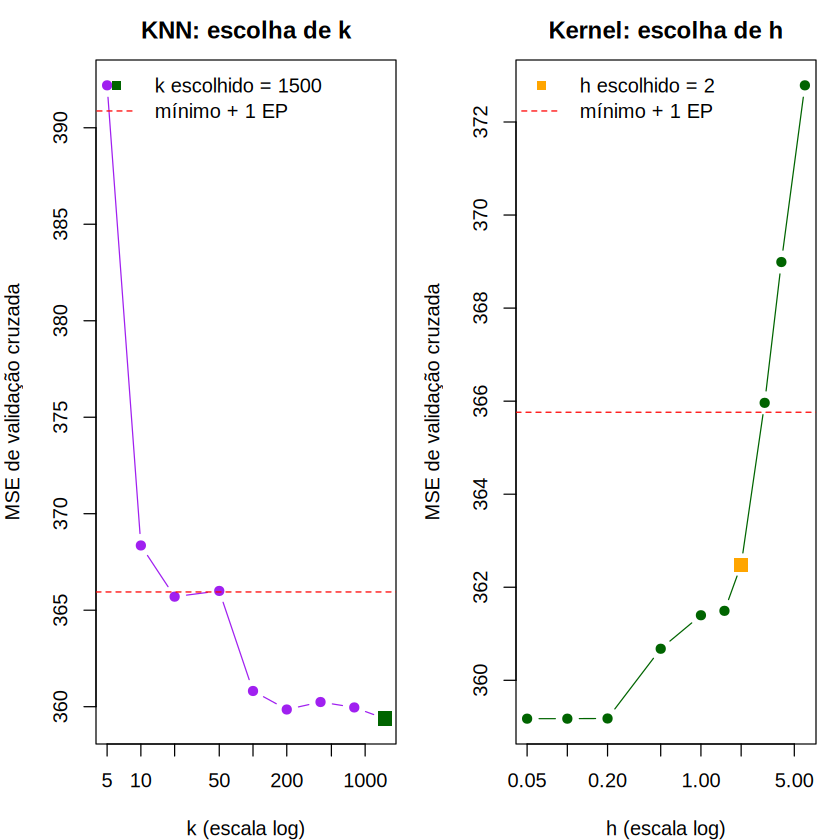

 ESCOLARIDADE_NUM    n media_obs reta diferenca
              2.0 2197      76.4 72.6       3.8
              5.5 4189      69.8 69.3       0.5
              6.0 2051      64.3 68.9      -4.6
              9.5 5034      63.8 65.6      -1.8
             14.0 1529      66.8 61.4       5.4

O suavizador supera a reta por mais de 1 EP: há curvatura que a reta não captura.


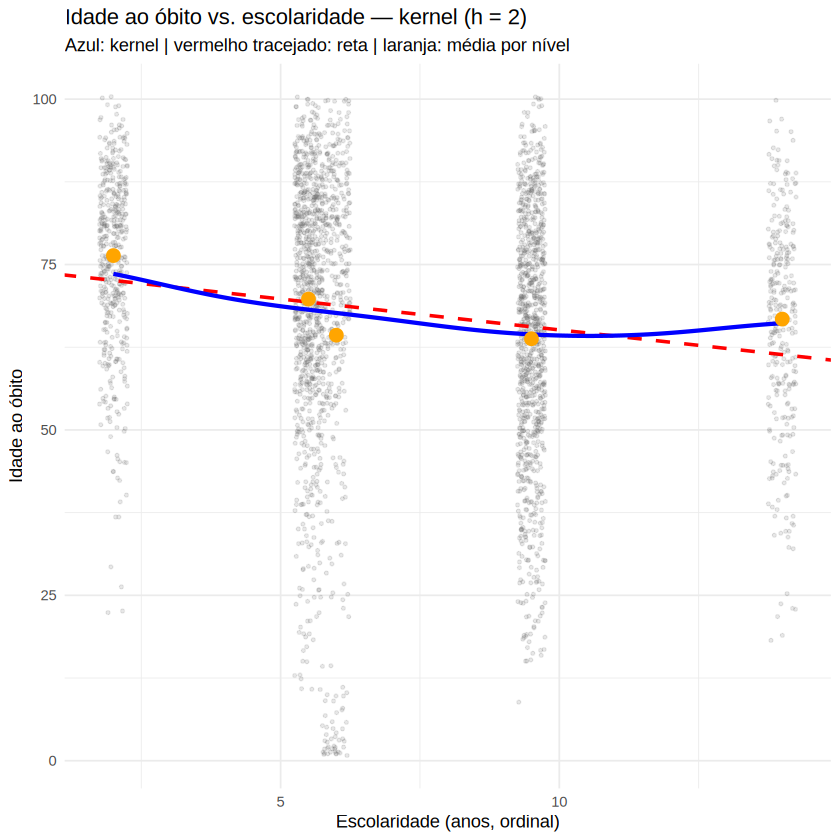

In [ ]:

library(ggplot2)

par(mfrow = c(1, 2), mar = c(4, 4, 2.5, 1))
plot(tab_knn$par, tab_knn$mse, type = "b", log = "x", pch = 19, col = "purple",
     xlab = "k (escala log)", ylab = "MSE de validação cruzada",
     main = "KNN: escolha de k")
abline(h = esc_k$limite, col = "red", lty = 2)
points(k_escolhido, tab_knn$mse[tab_knn$par == k_escolhido], pch = 15, cex = 1.6, col = "darkgreen")
legend("topright", c(paste("k escolhido =", k_escolhido), "mínimo + 1 EP"),
       col = c("darkgreen", "red"), pch = c(15, NA), lty = c(NA, 2), bty = "n")

plot(tab_ker$par, tab_ker$mse, type = "b", log = "x", pch = 19, col = "darkgreen",
     xlab = "h (escala log)", ylab = "MSE de validação cruzada",
     main = "Kernel: escolha de h")
abline(h = esc_h$limite, col = "red", lty = 2)
points(h_escolhido, tab_ker$mse[tab_ker$par == h_escolhido], pch = 15, cex = 1.6, col = "orange")
legend("topleft", c(paste("h escolhido =", h_escolhido), "mínimo + 1 EP"),
       col = c("orange", "red"), pch = c(15, NA), lty = c(NA, 2), bty = "n")
par(mfrow = c(1, 1))


set.seed(1)
amostra_plot <- treino_sub[sample(nrow(treino_sub), min(3000, nrow(treino_sub))), ]
grade <- seq(min(x_cv), max(x_cv), length.out = 200)
curva <- data.frame(ESCOLARIDADE_NUM = grade, IDADE = nw_pred(x_cv, y_cv, grade, h_escolhido))
medias_nivel <- aggregate(IDADE ~ ESCOLARIDADE_NUM, data = treino_sub, FUN = mean)

print(
  ggplot(amostra_plot, aes(ESCOLARIDADE_NUM, IDADE)) +
    geom_jitter(width = 0.25, alpha = 0.15, size = 0.8, colour = "grey40") +
    geom_abline(intercept = coef(m_reta)[1], slope = coef(m_reta)[2],
                colour = "red", linetype = "dashed", linewidth = 1) +
    geom_line(data = curva, colour = "blue", linewidth = 1.2) +
    geom_point(data = medias_nivel, colour = "orange", size = 3.5) +
    labs(title = paste0("Idade ao óbito vs. escolaridade — kernel (h = ", h_escolhido, ")"),
         subtitle = "Azul: kernel | vermelho tracejado: reta | laranja: média por nível",
         x = "Escolaridade (anos, ordinal)", y = "Idade ao óbito") +
    theme_minimal()
)

comp <- data.frame(
  ESCOLARIDADE_NUM = medias_nivel$ESCOLARIDADE_NUM,
  n = as.vector(table(treino_sub$ESCOLARIDADE_NUM)[as.character(medias_nivel$ESCOLARIDADE_NUM)]),
  media_obs = round(medias_nivel$IDADE, 1),
  reta = round(predict(m_reta, data.frame(ESCOLARIDADE_NUM = medias_nivel$ESCOLARIDADE_NUM)), 1)
)
comp$diferenca <- comp$media_obs - comp$reta
print(comp, row.names = FALSE)


if (min(tab_knn$mse) <= min(tab_ker$mse)) {
  mse_suav <- min(tab_knn$mse); ep_suav <- tab_knn$ep[which.min(tab_knn$mse)]
} else {
  mse_suav <- min(tab_ker$mse); ep_suav <- tab_ker$ep[which.min(tab_ker$mse)]
}
if (cv_reta["mse"] <= mse_suav + ep_suav) {
  cat("\nA reta está dentro de 1 EP do melhor suavizador: fique com a reta.\n")
} else {
  cat("\nO suavizador supera a reta por mais de 1 EP: há curvatura que a reta não captura.\n")
}